# 03 — Persiapan Pencarian Bilingual SmartLibrary AI

## Tujuan

Notebook ini bertujuan menyiapkan pemrosesan bahasa agar SmartLibrary AI dapat menerima permintaan buku dalam bahasa Indonesia dan bahasa Inggris.

### Metode
1. Memuat dataset buku hasil pembersihan.
2. Menganalisis karakteristik teks dataset.
3. Menormalisasi input pencarian pengguna.
4. Menyiapkan penerjemahan permintaan bahasa Indonesia ke bahasa Inggris.
5. Menguji hasil pemrosesan kedua bahasa.

**Catatan:** Dataset asli dan dataset hasil pembersihan tidak dimodifikasi pada tahap ini.

## Tujuan dan keluaran

- Evaluasi bahasa asli judul, kategori, dan deskripsi.
- Tentukan pemetaan kategori dan istilah bilingual.
- Jika terjemahan dipakai, simpan teks sumber dan catat metode terjemahan.
- Uji contoh kueri Indonesia sebelum menerjemahkan seluruh korpus.
- Simpan dataset/processed/books_indonesia.csv bila strategi dipilih.

## Tahapan yang akan dikerjakan

1. Evaluasi bahasa asli judul, kategori, dan deskripsi.
2. Tentukan pemetaan kategori dan istilah bilingual.
3. Jika terjemahan dipakai, simpan teks sumber dan catat metode terjemahan.
4. Uji contoh kueri Indonesia sebelum menerjemahkan seluruh korpus.
5. Simpan dataset/processed/books_indonesia.csv bila strategi dipilih.

## Catatan

Tahap ini akan diisi dengan kode per cell dan penjelasan yang lengkap ketika kita memulai notebook terkait. Jangan menyimpan hasil olahan ke `dataset/raw/`.

In [1]:

from pathlib import Path
import pandas as pd

# =====================================================
# CELL 2 - MEMBACA DATASET HASIL PEMBERSIHAN
# =====================================================

# Menemukan folder utama project
current_dir = Path.cwd().resolve()

ROOT = next(
    (
        folder for folder in [current_dir, *current_dir.parents]
        if (folder / "dataset" / "processed" / "books_clean.csv").is_file()
    ),
    None
)

if ROOT is None:
    raise FileNotFoundError(
        "books_clean.csv tidak ditemukan. "
        "Periksa folder dataset/processed/."
    )

# Lokasi dataset hasil pembersihan
DATA_PATH = ROOT / "dataset" / "processed" / "books_clean.csv"

# Membaca dataset
df_books = pd.read_csv(
    DATA_PATH,
    dtype={
        "isbn13": "string",
        "isbn10": "string"
    }
)

print("=" * 50)
print("SMARTLIBRARY AI - PERSIAPAN BILINGUAL")
print("=" * 50)

print("Project       :", ROOT)
print("Dataset       :", DATA_PATH)
print("Jumlah buku   :", len(df_books))
print("Jumlah kolom  :", len(df_books.columns))

print("\n[OK] Dataset berhasil dibaca.")

# Menampilkan 5 data pertama
display(
    df_books[
        ["isbn13", "title", "authors", "categories", "description"]
    ].head()
)


SMARTLIBRARY AI - PERSIAPAN BILINGUAL
Project       : D:\Project\SmartLibrary_AI
Dataset       : D:\Project\SmartLibrary_AI\dataset\processed\books_clean.csv
Jumlah buku   : 5094
Jumlah kolom  : 24

[OK] Dataset berhasil dibaca.


,isbn13,title,authors,categories,description
0,9780425197455,10 Lb. Penalty,Dick Francis,Fiction,Entering the political arena as the trusted co...
1,9781579905088,1000 Rings,Marthe Le Van,Crafts & Hobbies,An extensive and diverse collection of one tho...
2,9780486256078,1001 Illuminated Initial Letters,Owen Jones,Design,The illuminated letters in this volume by the ...
3,9780060540944,1421,Gavin Menzies,History,"Based on 15 years of in-depth research, ""1421""..."
4,9781400032051,1491,Charles C. Mann,History,Describes how recent archaeological research h...


In [2]:

# =====================================================
# CELL 3 - VALIDASI DATASET
# =====================================================

# Kolom yang diperlukan
required_columns = [
    "isbn13",
    "title",
    "authors",
    "categories",
    "description",
    "combined_text",
    "book_key"
]

# Memeriksa kolom yang belum tersedia
missing_columns = [
    col for col in required_columns
    if col not in df_books.columns
]

assert not missing_columns, (
    f"Kolom tidak ditemukan: {missing_columns}"
)

# Memastikan setiap buku memiliki identitas unik
assert df_books["isbn13"].is_unique, (
    "Terdapat ISBN duplikat!"
)

assert df_books["book_key"].is_unique, (
    "Terdapat kelompok buku berulang!"
)

# Memastikan teks untuk TF-IDF tersedia
assert df_books["combined_text"].notna().all(), (
    "Terdapat combined_text kosong!"
)

assert (
    df_books["combined_text"]
    .astype("string")
    .str.strip()
    .ne("")
    .all()
), "Terdapat teks rekomendasi kosong!"

# Ringkasan
print("=" * 50)
print("HASIL VALIDASI DATASET")
print("=" * 50)

print("Jumlah buku       :", len(df_books))
print("Kolom tersedia    :", len(df_books.columns))
print("ISBN unik         :", df_books["isbn13"].is_unique)
print("Kelompok unik     :", df_books["book_key"].is_unique)
print("Teks siap TF-IDF  : Ya")

print("\n[OK] Validasi berhasil.")
print("[OK] Dataset siap untuk pemrosesan bilingual.")


HASIL VALIDASI DATASET
Jumlah buku       : 5094
Kolom tersedia    : 24
ISBN unik         : True
Kelompok unik     : True
Teks siap TF-IDF  : Ya

[OK] Validasi berhasil.
[OK] Dataset siap untuk pemrosesan bilingual.


STATISTIK PANJANG DESKRIPSI


,description_length,description_words
count,5094.00,5094.00
mean,489.15,79.38
std,424.30,68.92
min,124.00,25.00
25%,221.00,35.00
50%,293.00,48.00
75%,650.75,106.00
max,5786.00,920.00



Jumlah buku: 5094


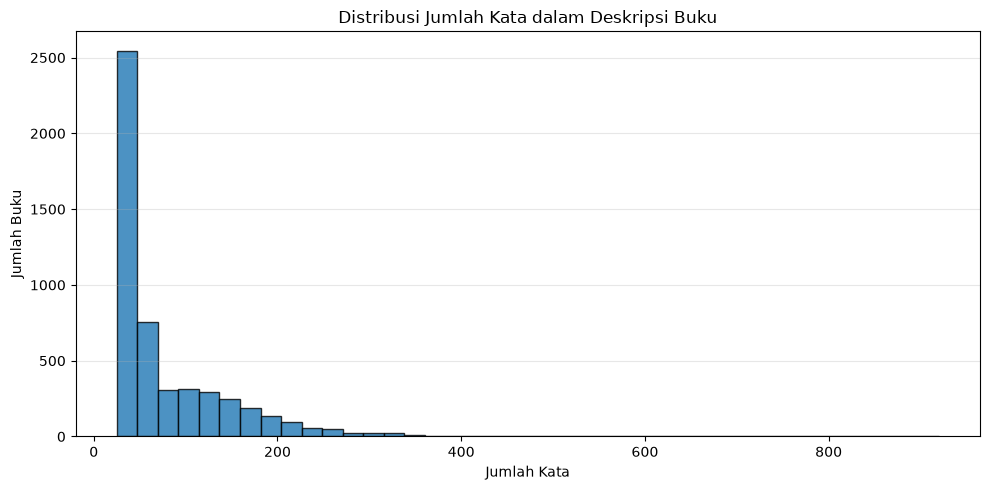

In [3]:

# =====================================================
# CELL 4 - ANALISIS PANJANG DESKRIPSI BUKU
# =====================================================

import matplotlib.pyplot as plt

# Membuat salinan untuk analisis
df_analysis = df_books.copy()

# Menghitung jumlah karakter deskripsi
df_analysis["description_length"] = (
    df_analysis["description"]
    .fillna("")
    .astype(str)
    .str.len()
)

# Menghitung jumlah kata deskripsi
df_analysis["description_words"] = (
    df_analysis["description"]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

print("STATISTIK PANJANG DESKRIPSI")
display(
    df_analysis[
        ["description_length", "description_words"]
    ].describe().round(2)
)

print("\nJumlah buku:", len(df_analysis))

# Visualisasi distribusi panjang deskripsi
plt.figure(figsize=(10, 5))

plt.hist(
    df_analysis["description_words"],
    bins=40,
    edgecolor="black",
    alpha=0.8
)

plt.title("Distribusi Jumlah Kata dalam Deskripsi Buku")
plt.xlabel("Jumlah Kata")
plt.ylabel("Jumlah Buku")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [4]:

# =====================================================
# CELL 5 - PEMERIKSAAN CONTOH TEKS
# =====================================================

# Mengambil 10 contoh buku secara acak
sample_books = df_analysis.sample(
    n=min(10, len(df_analysis)),
    random_state=42
)

for i, (_, book) in enumerate(
    sample_books.iterrows(), start=1
):
    print("=" * 65)
    print(f"BUKU {i}")
    print("=" * 65)

    print("Judul    :", book["title"])
    print("Kategori :", book["categories"])

    print("\nDeskripsi:")
    print(str(book["description"])[:400])

    print()


BUKU 1
Judul    : Down to the Bonny Glen
Kategori : Juvenile Fiction

Deskripsi:
With the arrival of her new governess, Miss Crow, Martha begins to see that her work is quite important and soon realizes she could learn a great deal from her if she only took the time to get to know her. Simultaneous.

BUKU 2
Judul    : The Complete Short Prose, 1929-1989
Kategori : Fiction

Deskripsi:
Gathers the Nobel Prize winning poet and dramatist's short prose into one volume that affords the reader a view of Beckett's development as an artist

BUKU 3
Judul    : Daisy Miller and Other Stories
Kategori : Fiction

Deskripsi:
The tale of Daisy's irruption into staid European society enjoyed, as did Daisy herself, asuccès de scandale; and it has remained one of Jamess most popular short stories. Like the others collected here--'Pandora,' 'The Patagonia,' and 'Four Meetings'-- it describes a confrontation between different values in a changing world. Is the new independent American girl enchanting in he

HASIL IDENTIFIKASI BAHASA
Jumlah sampel: 300


,Bahasa,Jumlah Buku,Persentase (%)
0,en,300,100.0


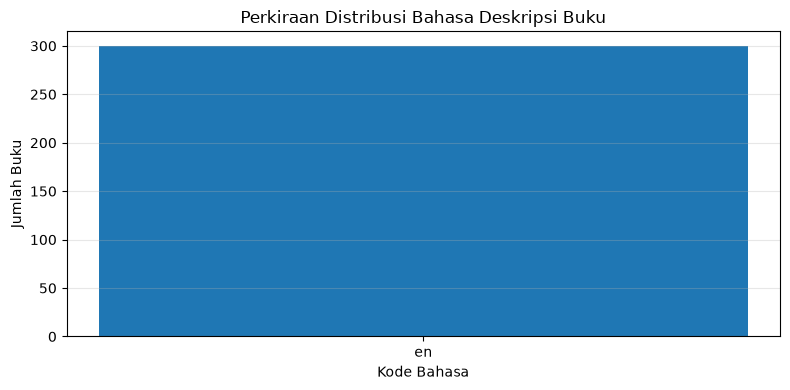

In [6]:

# =====================================================
# CELL 7 - ANALISIS DISTRIBUSI BAHASA
# =====================================================

from langdetect import detect, DetectorFactory
from langdetect.lang_detect_exception import LangDetectException

# Agar hasil deteksi dapat direproduksi
DetectorFactory.seed = 42

def detect_book_language(text):
    """
    Mengidentifikasi perkiraan bahasa deskripsi buku.
    Mengembalikan kode bahasa atau 'unknown'.
    """

    if pd.isna(text):
        return "unknown"

    text = str(text).strip()

    # Teks sangat pendek tidak dianalisis
    if len(text) < 100:
        return "unknown"

    try:
        return detect(text)
    except LangDetectException:
        return "unknown"


# Mengambil sampel acak
df_language_sample = df_analysis.sample(
    n=min(300, len(df_analysis)),
    random_state=42
).copy()

# Deteksi bahasa
df_language_sample["detected_language"] = (
    df_language_sample["description"]
    .apply(detect_book_language)
)

# Distribusi bahasa
language_summary = (
    df_language_sample["detected_language"]
    .value_counts()
    .rename_axis("Bahasa")
    .reset_index(name="Jumlah Buku")
)

language_summary["Persentase (%)"] = (
    language_summary["Jumlah Buku"]
    / len(df_language_sample) * 100
).round(2)

print("=" * 50)
print("HASIL IDENTIFIKASI BAHASA")
print("=" * 50)

print("Jumlah sampel:", len(df_language_sample))
display(language_summary)

# Visualisasi
plt.figure(figsize=(8, 4))

plt.bar(
    language_summary["Bahasa"],
    language_summary["Jumlah Buku"]
)

plt.title("Perkiraan Distribusi Bahasa Deskripsi Buku")
plt.xlabel("Kode Bahasa")
plt.ylabel("Jumlah Buku")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [7]:

# =====================================================
# CELL 8 - NORMALISASI INPUT PENGGUNA
# =====================================================

import re
import html
import unicodedata

def normalize_query(text):
    """
    Normalisasi input pencarian pengguna.

    Proses:
    1. Membersihkan HTML entities
    2. Normalisasi Unicode
    3. Menghapus URL dan HTML tags
    4. Mengubah huruf menjadi lowercase
    5. Menghapus tanda baca
    6. Merapikan spasi
    """

    # Menangani input kosong
    if text is None or not str(text).strip():
        return ""

    text = str(text)

    # Membersihkan HTML entities
    text = html.unescape(text)

    # Normalisasi Unicode
    text = unicodedata.normalize("NFKC", text)

    # Menghapus URL
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text,
        flags=re.IGNORECASE
    )

    # Menghapus HTML tags
    text = re.sub(r"<[^>]*>", " ", text)

    # Mengubah menjadi huruf kecil
    text = text.casefold()

    # Menghapus tanda baca
    text = re.sub(r"[^\w\s]", " ", text)

    # Mengganti underscore dengan spasi
    text = re.sub(r"_+", " ", text)

    # Merapikan spasi
    text = re.sub(r"\s+", " ", text).strip()

    return text


print("[OK] Fungsi normalize_query berhasil dibuat.")


[OK] Fungsi normalize_query berhasil dibuat.


In [8]:

# =====================================================
# CELL 9 - PENGUJIAN NORMALISASI QUERY
# =====================================================

# Contoh input pencarian
test_queries = [
    "Saya ingin buku tentang Artificial Intelligence!",
    "Books about Machine Learning & Data Science.",
    "Novel Misteri dan Detektif",
    "Psychology, Human Behavior & Mental Health",
    "Buku tentang Sejarah Dunia!!!",
    "   Deep Learning    for Beginners   ",
    ""
]

# Menampilkan perbandingan
query_results = []

for query in test_queries:
    query_results.append({
        "Input Asli": query,
        "Hasil Normalisasi": normalize_query(query)
    })

df_query_test = pd.DataFrame(query_results)

display(df_query_test)


,Input Asli,Hasil Normalisasi
0,Saya ingin buku tentang Artificial Intelligence!,saya ingin buku tentang artificial intelligence
1,Books about Machine Learning & Data Science.,books about machine learning data science
2,Novel Misteri dan Detektif,novel misteri dan detektif
3,"Psychology, Human Behavior & Mental Health",psychology human behavior mental health
4,Buku tentang Sejarah Dunia!!!,buku tentang sejarah dunia
5,Deep Learning for Beginners,deep learning for beginners
6,,


In [9]:

# =====================================================
# CELL 10 - VALIDASI NORMALISASI QUERY
# =====================================================

# Input kosong
assert normalize_query("") == ""

# Input spasi
assert normalize_query("   ") == ""

# Lowercase
assert normalize_query("MACHINE LEARNING") == "machine learning"

# Tanda baca
assert normalize_query("AI & Robotics!") == "ai robotics"

# Spasi berlebih
assert normalize_query("Deep    Learning") == "deep learning"

# Input bahasa Indonesia
assert (
    normalize_query("Buku tentang Sejarah Dunia!")
    == "buku tentang sejarah dunia"
)

print("=" * 50)
print("VALIDASI NORMALISASI QUERY")
print("=" * 50)

print("[OK] Input kosong ditangani.")
print("[OK] Lowercase berhasil.")
print("[OK] Tanda baca dibersihkan.")
print("[OK] Spasi berlebih dibersihkan.")
print("[OK] Input Indonesia dapat dinormalisasi.")

print("\n[OK] Seluruh pengujian berhasil.")


VALIDASI NORMALISASI QUERY
[OK] Input kosong ditangani.
[OK] Lowercase berhasil.
[OK] Tanda baca dibersihkan.
[OK] Spasi berlebih dibersihkan.
[OK] Input Indonesia dapat dinormalisasi.

[OK] Seluruh pengujian berhasil.


In [14]:

# =====================================================
# CELL 12 - FUNGSI QUERY BILINGUAL (MYMEMORY)
# =====================================================

from deep_translator import MyMemoryTranslator
from langdetect import detect, DetectorFactory
from langdetect.lang_detect_exception import LangDetectException
from functools import lru_cache
import re

DetectorFactory.seed = 42


def detect_query_language(text):
    """
    Memperkirakan bahasa input pengguna.
    """
    if not text or not text.strip():
        return "unknown"

    try:
        return detect(text)
    except LangDetectException:
        return "unknown"


@lru_cache(maxsize=256)
def translate_id_to_en(text):
    """
    Menerjemahkan teks Indonesia ke Inggris.
    Hasil disimpan dalam cache agar input sama
    tidak selalu mengirim permintaan baru.
    """

    translator = MyMemoryTranslator(
        source="id-ID",
        target="en-GB"
    )

    result = translator.translate(text)

    if not result or not str(result).strip():
        raise RuntimeError("Hasil penerjemahan kosong.")

    return str(result).strip()


def prepare_bilingual_query(query, language="auto"):
    """
    Memproses input pencarian buku.

    language:
      auto : deteksi bahasa otomatis
      id   : bahasa Indonesia
      en   : bahasa Inggris
    """

    if language not in {"auto", "id", "en"}:
        raise ValueError(
            "Pilihan bahasa harus auto, id, atau en."
        )

    # Membersihkan spasi input
    original_query = re.sub(
        r"\s+", " ", str(query or "")
    ).strip()

    # Menangani input kosong
    if not original_query:
        return {
            "original_query": "",
            "detected_language": "unknown",
            "english_query": "",
            "normalized_query": "",
            "translated": False
        }

    # Menentukan bahasa
    if language == "auto":
        detected_language = detect_query_language(
            original_query
        )
    else:
        detected_language = language

    # Hindari menerjemahkan dari bahasa yang
    # tidak berhasil dikenali sebagai id/en
    if detected_language not in {"id", "en"}:
        raise RuntimeError(
            "Bahasa input tidak teridentifikasi "
            "sebagai Indonesia atau Inggris. "
            "Pilih bahasa secara manual."
        )

    # Jika bahasa Inggris, langsung digunakan
    if detected_language == "en":
        english_query = original_query
        translated = False

    # Jika bahasa Indonesia, diterjemahkan
    else:
        try:
            english_query = translate_id_to_en(
                original_query
            )
        except Exception as error:
            raise RuntimeError(
                "Penerjemahan MyMemory gagal. "
                f"{type(error).__name__}: {error}"
            ) from error

        translated = True

    # Normalisasi hasil akhir
    normalized_query = normalize_query(
        english_query
    )

    return {
        "original_query": original_query,
        "detected_language": detected_language,
        "english_query": english_query,
        "normalized_query": normalized_query,
        "translated": translated
    }


print("[OK] Fungsi bilingual menggunakan MyMemory.")


[OK] Fungsi bilingual menggunakan MyMemory.


In [15]:

# =====================================================
# CELL 13 - PENGUJIAN BILINGUAL
# =====================================================

test_queries = [
    ("Saya ingin buku tentang psikologi dan perilaku manusia", "id"),
    ("I want books about psychology and human behavior", "en"),
    ("Saya ingin membaca novel misteri tentang pembunuhan", "id"),
    ("Books about world history", "en"),
    ("Buku tentang filsafat dan kehidupan", "id")
]

results = []

for query, language in test_queries:
    try:
        result = prepare_bilingual_query(
            query,
            language=language
        )

        results.append({
            "Input": result["original_query"],
            "Bahasa": result["detected_language"],
            "Terjemahan": result["english_query"],
            "Normalisasi": result["normalized_query"],
            "Status": "Berhasil"
        })

    except Exception as error:
        results.append({
            "Input": query,
            "Bahasa": language,
            "Terjemahan": "-",
            "Normalisasi": "-",
            "Status": str(error)
        })

df_translation_test = pd.DataFrame(results)

display(df_translation_test)


,Input,Bahasa,Terjemahan,Normalisasi,Status
0,Saya ingin buku tentang psikologi dan perilaku...,id,I want a book about psychology and human behav...,i want a book about psychology and human behav...,Berhasil
1,I want books about psychology and human behavior,en,I want books about psychology and human behavior,i want books about psychology and human behavior,Berhasil
2,Saya ingin membaca novel misteri tentang pembu...,id,I want to read a mystery novel about murder.,i want to read a mystery novel about murder,Berhasil
3,Books about world history,en,Books about world history,books about world history,Berhasil
4,Buku tentang filsafat dan kehidupan,id,Books on philosophy and life,books on philosophy and life,Berhasil


In [16]:

# =====================================================
# CELL 14 - VALIDASI HASIL PENGUJIAN BILINGUAL
# =====================================================

# Menghitung keberhasilan pengujian
total_test = len(df_translation_test)

successful_test = (
    df_translation_test["Status"] == "Berhasil"
).sum()

# Memastikan semua pengujian berhasil
assert successful_test == total_test, (
    "Masih ada pengujian penerjemahan yang gagal!"
)

# Memastikan hasil terjemahan tersedia
assert (
    df_translation_test["Normalisasi"]
    .astype(str)
    .str.strip()
    .ne("")
    .all()
), "Terdapat hasil normalisasi kosong!"

print("=" * 50)
print("VALIDASI PENERJEMAHAN BILINGUAL")
print("=" * 50)

print("Total pengujian :", total_test)
print("Berhasil        :", successful_test)
print("Gagal           :", total_test - successful_test)

print("\n[OK] Validasi bilingual berhasil.")


VALIDASI PENERJEMAHAN BILINGUAL
Total pengujian : 5
Berhasil        : 5
Gagal           : 0

[OK] Validasi bilingual berhasil.


In [17]:

# =====================================================
# CELL 15 - PENGUJIAN MODUL BILINGUAL
# =====================================================

import sys
import importlib

# Memastikan folder project dapat diakses
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Mengimpor modul bilingual
import src.bilingual as bilingual

# Memuat ulang modul jika baru diedit
importlib.reload(bilingual)

# Pengujian bahasa Inggris
result_en = bilingual.prepare_bilingual_query(
    "Books about world history",
    language="en"
)

# Pengujian bahasa Indonesia
result_id = bilingual.prepare_bilingual_query(
    "Saya ingin buku tentang psikologi",
    language="id"
)

# Validasi
assert result_en["translated"] is False
assert result_id["translated"] is True

assert result_en["normalized_query"] != ""
assert result_id["normalized_query"] != ""

print("=" * 50)
print("PENGUJIAN MODUL BILINGUAL")
print("=" * 50)

print("\nBAHASA INGGRIS")
print("Input :", result_en["original_query"])
print("Query :", result_en["normalized_query"])

print("\nBAHASA INDONESIA")
print("Input :", result_id["original_query"])
print("Query :", result_id["normalized_query"])

print("\n[OK] Modul bilingual berhasil digunakan.")


PENGUJIAN MODUL BILINGUAL

BAHASA INGGRIS
Input : Books about world history
Query : books about world history

BAHASA INDONESIA
Input : Saya ingin buku tentang psikologi
Query : i want a book on psychology

[OK] Modul bilingual berhasil digunakan.
